Reading snapshot: particles-80.vtu
time of simulation =  0.08
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 900
  Number of cells:
    vertex: 900
  Point data: x, cut-off-radius, association, partid, v, a, u, mass, density, pressure, f, Omega, rho_dh, Ncount, wcount, wcount_dh, soundSpeed, timeStepSize, smoothingLength, smoothingLengthPrevious, hDot, residual, hasConverged, iterCount, hLeft, hRight, isBoundaryParticle, hasNoNeighbours, rot_v, div_v, v_sig_AV, balsara>
********************************************


<Figure size 432x288 with 0 Axes>

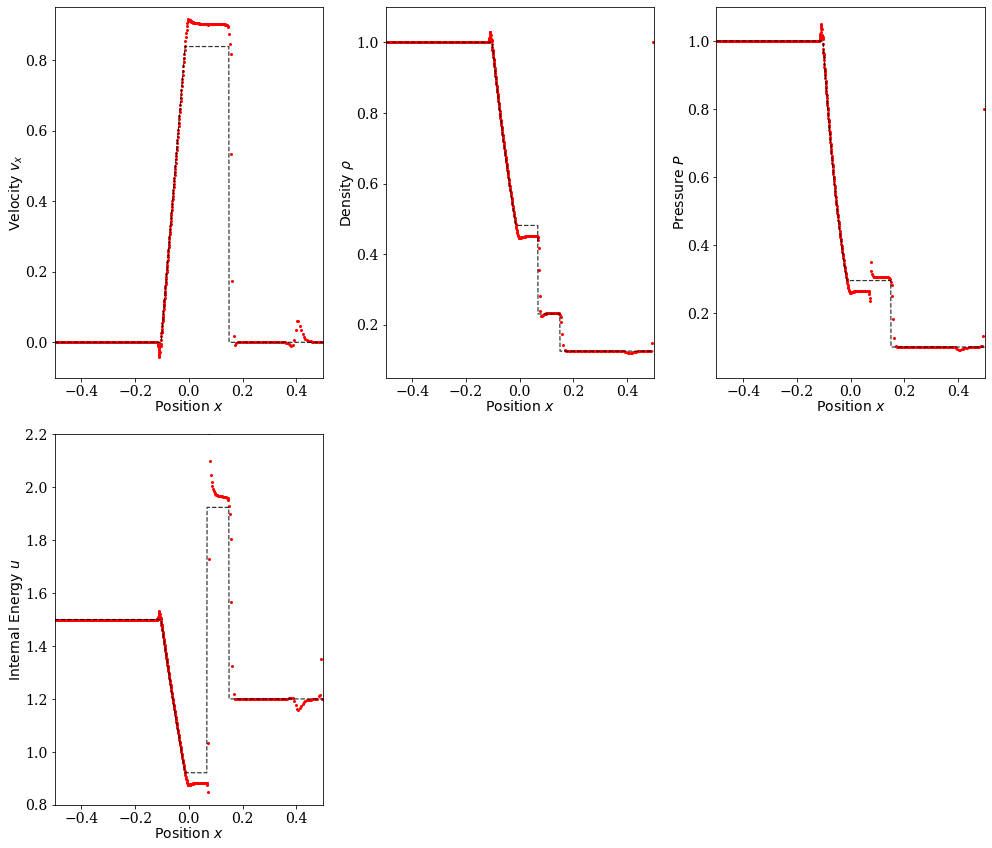

In [14]:
# Parameters
gas_gamma = 5.0 / 3.0  # Polytropic index
rho_L = 1.0  # Density left state
rho_R = 0.125  # Density right state
v_L = 0.0  # Velocity left state
v_R = 0.0  # Velocity right state
P_L = 1.0  # Pressure left state
P_R = 0.1  # Pressure right state

# Solution parameters
N = 1000  # Number of points
x_min = -0.5
x_max = 0.5

plot_alpha = False
plot_alpha_diff = False

import matplotlib

from pylab import *

import meshio
import glob, os

"""
Import particle snapshot file
"""

snapshot_dir = ''
snapshot_number = 80
files = sorted(glob.glob(snapshot_dir + "*.vtu"), key=len)

# Simulation Parameters
time_step_sim = 1e-4
snapshot_rate = 10
time = float(snapshot_number)*snapshot_rate*time_step_sim

snapshot = files[snapshot_number]
print('Reading snapshot: ' + snapshot )
print("time of simulation = ", time)
print("********************************************")

mesh = meshio.read( snapshot )
print(mesh.point_data_to_sets)
print("********************************************")

# Extract Fields
pos = mesh.point_data["x"]
x = pos[:,0]
y = pos[:,1]
vel = mesh.point_data["v"]
v = vel[:,0]
P = mesh.point_data["pressure"][:,0]
u = mesh.point_data["u"][:,0]
rho = mesh.point_data["density"][:,0]

x += x_min

# ---------------------------------------------------------------
# Don't touch anything after this.
# ---------------------------------------------------------------

c_L = sqrt(gas_gamma * P_L / rho_L)  # Speed of the rarefaction wave
c_R = sqrt(gas_gamma * P_R / rho_R)  # Speed of the shock front

# Helpful variable
Gama = (gas_gamma - 1.0) / (gas_gamma + 1.0)
beta = (gas_gamma - 1.0) / (2.0 * gas_gamma)

# Characteristic function and its derivative, following Toro (2009)
def compute_f(P_3, P, c):
    u = P_3 / P
    if u > 1:
        term1 = gas_gamma * ((gas_gamma + 1.0) * u + gas_gamma - 1.0)
        term2 = sqrt(2.0 / term1)
        fp = (u - 1.0) * c * term2
        dfdp = (
            c * term2 / P
            + (u - 1.0)
            * c
            / term2
            * (-1.0 / term1 ** 2)
            * gas_gamma
            * (gas_gamma + 1.0)
            / P
        )
    else:
        fp = (u ** beta - 1.0) * (2.0 * c / (gas_gamma - 1.0))
        dfdp = 2.0 * c / (gas_gamma - 1.0) * beta * u ** (beta - 1.0) / P
    return (fp, dfdp)


# Solution of the Riemann problem following Toro (2009)
def RiemannProblem(rho_L, P_L, v_L, rho_R, P_R, v_R):
    P_new = (
        (c_L + c_R + (v_L - v_R) * 0.5 * (gas_gamma - 1.0))
        / (c_L / P_L ** beta + c_R / P_R ** beta)
    ) ** (1.0 / beta)
    P_3 = 0.5 * (P_R + P_L)
    f_L = 1.0
    while fabs(P_3 - P_new) > 1e-6:
        P_3 = P_new
        (f_L, dfdp_L) = compute_f(P_3, P_L, c_L)
        (f_R, dfdp_R) = compute_f(P_3, P_R, c_R)
        f = f_L + f_R + (v_R - v_L)
        df = dfdp_L + dfdp_R
        dp = -f / df
        prnew = P_3 + dp
    v_3 = v_L - f_L
    return (P_new, v_3)


# Solve Riemann problem for post-shock region
(P_3, v_3) = RiemannProblem(rho_L, P_L, v_L, rho_R, P_R, v_R)

# Check direction of shocks and wave
shock_R = P_3 > P_R
shock_L = P_3 > P_L

# Velocity of shock front and and rarefaction wave
if shock_R:
    v_right = v_R + c_R ** 2 * (P_3 / P_R - 1.0) / (gas_gamma * (v_3 - v_R))
else:
    v_right = c_R + 0.5 * (gas_gamma + 1.0) * v_3 - 0.5 * (gas_gamma - 1.0) * v_R

if shock_L:
    v_left = v_L + c_L ** 2 * (P_3 / p_L - 1.0) / (gas_gamma * (v_3 - v_L))
else:
    v_left = c_L - 0.5 * (gas_gamma + 1.0) * v_3 + 0.5 * (gas_gamma - 1.0) * v_L

# Compute position of the transitions
x_23 = -fabs(v_left) * time
if shock_L:
    x_12 = -fabs(v_left) * time
else:
    x_12 = -(c_L - v_L) * time

x_34 = v_3 * time

x_45 = fabs(v_right) * time
if shock_R:
    x_56 = fabs(v_right) * time
else:
    x_56 = (c_R + v_R) * time


# Prepare arrays
delta_x = (x_max - x_min) / N
x_s = arange(x_min, x_max, delta_x)
rho_s = zeros(N)
P_s = zeros(N)
v_s = zeros(N)

# Compute solution in the different regions
for i in range(N):
    if x_s[i] <= x_12:
        rho_s[i] = rho_L
        P_s[i] = P_L
        v_s[i] = v_L
    if x_s[i] >= x_12 and x_s[i] < x_23:
        if shock_L:
            rho_s[i] = rho_L * (Gama + P_3 / P_L) / (1.0 + Gama * P_3 / P_L)
            P_s[i] = P_3
            v_s[i] = v_3
        else:
            rho_s[i] = rho_L * (
                Gama * (0.0 - x_s[i]) / (c_L * time) + Gama * v_L / c_L + (1.0 - Gama)
            ) ** (2.0 / (gas_gamma - 1.0))
            P_s[i] = P_L * (rho_s[i] / rho_L) ** gas_gamma
            v_s[i] = (1.0 - Gama) * (c_L - (0.0 - x_s[i]) / time) + Gama * v_L
    if x_s[i] >= x_23 and x_s[i] < x_34:
        if shock_L:
            rho_s[i] = rho_L * (Gama + P_3 / P_L) / (1 + Gama * P_3 / p_L)
        else:
            rho_s[i] = rho_L * (P_3 / P_L) ** (1.0 / gas_gamma)
        P_s[i] = P_3
        v_s[i] = v_3
    if x_s[i] >= x_34 and x_s[i] < x_45:
        if shock_R:
            rho_s[i] = rho_R * (Gama + P_3 / P_R) / (1.0 + Gama * P_3 / P_R)
        else:
            rho_s[i] = rho_R * (P_3 / P_R) ** (1.0 / gas_gamma)
        P_s[i] = P_3
        v_s[i] = v_3
    if x_s[i] >= x_45 and x_s[i] < x_56:
        if shock_R:
            rho_s[i] = rho_R
            P_s[i] = P_R
            v_s[i] = v_R
        else:
            rho_s[i] = rho_R * (
                Gama * (x_s[i]) / (c_R * time) - Gama * v_R / c_R + (1.0 - Gama)
            ) ** (2.0 / (gas_gamma - 1.0))
            P_s[i] = p_R * (rho_s[i] / rho_R) ** gas_gamma
            v_s[i] = (1.0 - Gama) * (-c_R - (-x_s[i]) / time) + Gama * v_R
    if x_s[i] >= x_56:
        rho_s[i] = rho_R
        P_s[i] = P_R
        v_s[i] = v_R


# Additional arrays
u_s = P_s / (rho_s * (gas_gamma - 1.0))  # internal energy
s_s = P_s / rho_s ** gas_gamma  # entropic function


# Plot the interesting quantities
figure()

# Plot Setup
font = {'size':14}
plt.rc('font', **font)
plt.rc('font', family='serif')
plt.rc('text', usetex=False)

figure(figsize=(14, 12))


# Velocity profile --------------------------------
subplot(231)
plot(x, v, ".", color="r", ms=4.0)
plot(x_s, v_s, "--", color="k", alpha=0.8, lw=1.2)
xlabel("${\\rm{Position}}~x$", labelpad=0)
ylabel("${\\rm{Velocity}}~v_x$", labelpad=0)
xlim(-0.5, 0.5)
ylim(-0.1, 0.95)

# Density profile --------------------------------
subplot(232)
if plot_alpha_diff:
    plot(x, alpha_diff, ".", color="r", ms=4.0)
    ylabel(r"${\rm{Diffusion}}~\alpha$", labelpad=0)
    # Show location of contact discontinuity
    plot([x_34, x_34], [-100, 100], color="k", alpha=0.5, ls="dashed", lw=1.2)
    ylim(0, 1)
else:
    plot(x, rho, ".", color="r", ms=4.0)
    plot(x_s, rho_s, "--", color="k", alpha=0.8, lw=1.2)
    ylabel("${\\rm{Density}}~\\rho$", labelpad=0)
    ylim(0.05, 1.1)

xlabel("${\\rm{Position}}~x$", labelpad=0)
xlim(-0.5, 0.5)

# Pressure profile --------------------------------
subplot(233)
plot(x, P, ".", color="r", ms=4.0)
plot(x_s, P_s, "--", color="k", alpha=0.8, lw=1.2)
xlabel("${\\rm{Position}}~x$", labelpad=0)
ylabel("${\\rm{Pressure}}~P$", labelpad=0)
xlim(-0.5, 0.5)
ylim(0.01, 1.1)

# Internal energy profile -------------------------
subplot(234)
plot(x, u, ".", color="r", ms=4.0)
plot(x_s, u_s, "--", color="k", alpha=0.8, lw=1.2)
xlabel("${\\rm{Position}}~x$", labelpad=0)
ylabel("${\\rm{Internal~Energy}}~u$", labelpad=0)
xlim(-0.5, 0.5)
ylim(0.8, 2.2)

# Information -------------------------------------

tight_layout()

show()
close()